# Phase 4A — Full DIV2K Pretraining from the Smoke Checkpoint
**Goal:** expand training from 100 to all 800 images without losing the learned generator.

The first full-data run starts from the **best generator weights** inside `pretrain_smoke_v1_smoke100/last.pt`. Adam starts fresh, and full-data epoch numbering starts at 0. The old smoke checkpoint is read only.

If the full-data run already has its own `last.pt`, that checkpoint takes priority: generator, Adam, and history resume from the last completed full-data epoch.

**Default:** 800 training images, the same 50 validation images, 20 full-data epochs, batch size 16. This gives 50 steps/epoch and 1,000 new optimizer updates. No discriminator, VGG, or held-out test images are used.

Budget roughly **35–50 minutes of training on a T4**, extrapolating from the earlier run, plus archive restoration if needed. The first epoch prints the measured duration; use it to estimate the rest. Results are not guaranteed to beat bicubic.


## 1. Update the project
The cell fast-forwards an existing clean main checkout. Local tracked edits are preserved: if present, the update stops instead of discarding them.


In [1]:
from pathlib import Path
import importlib
import json
import os
import subprocess
import sys

PROJECT_ROOT = Path("/content/SRGAN-Image-Super-Resolution")
REPO_URL = "https://github.com/ennaguiyoussef/SRGAN-Image-Super-Resolution.git"
if not PROJECT_ROOT.exists():
    subprocess.run(["git", "clone", "--branch", "main", REPO_URL, str(PROJECT_ROOT)], check=True)
else:
    if not (PROJECT_ROOT / ".git").is_dir():
        raise RuntimeError("Project folder exists but is not a Git checkout.")
    changes = subprocess.check_output(
        ["git", "-C", str(PROJECT_ROOT), "status", "--porcelain", "--untracked-files=no"],
        text=True,
    )
    if changes.strip():
        raise RuntimeError("Save local tracked edits before updating this checkout.")
    branch = subprocess.check_output(
        ["git", "-C", str(PROJECT_ROOT), "branch", "--show-current"], text=True
    ).strip()
    if branch != "main":
        raise RuntimeError("Select the main branch before running this notebook.")
    subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only", "origin", "main"], check=True)
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
importlib.invalidate_caches()
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
print("Project checkout ready.")


Project checkout ready.


## 2. Read full-data settings and verify the GPU
Settings come from `configs/pretrain_full.yaml`. MSE, batch size, learning rate, crop policy, and validation protocol match the smoke experiment.

The **20 epochs here belong to the new full-data run**. To continue it later, raise its total epoch target. Keep the same run name and other settings. The 100-epoch source experiment is kept separately.


In [2]:
import yaml
import torch
from src.setup import environment_report, load_config, seed_everything

config = load_config(PROJECT_ROOT / "configs/srgan.yaml")
pretrain = yaml.safe_load((PROJECT_ROOT / "configs/pretrain_full.yaml").read_text())
if pretrain["smoke_mode"] is not False:
    raise ValueError("This notebook requires the full 800-image dataset.")
if pretrain["num_workers"] != 0:
    raise ValueError("This phase uses num_workers=0 for epoch-boundary replay.")
report = environment_report()
print(json.dumps(report, indent=2))
if not report["cuda_available"]:
    raise RuntimeError("Select a GPU runtime before training.")
device = torch.device("cuda:0")
seed_everything(config["seed"])
print(json.dumps(pretrain, indent=2))


{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "cuda_runtime": "13.0",
  "cuda_available": true,
  "gpu": "Tesla T4"
}
{
  "smoke_mode": false,
  "epochs": 20,
  "learning_rate": 0.0001,
  "batch_size": 16,
  "gradient_clip_norm": 1.0,
  "num_workers": 0,
  "run_name": "pretrain_full_v1",
  "source_run": "pretrain_smoke_v1_smoke100",
  "resume": true
}


## 3. Mount Drive and restore only the images needed
Phase 2 must already have saved the manifest and the full HR archive cache. The notebook reuses local images and extracts missing selected images from Drive after a runtime reset. No held-out test images are read.


In [3]:
from google.colab import drive
from src.setup import prepare_directories
from src.data import extract_hr_archive, split_manifest
from src.dataset import SuperResolutionDataset

drive.mount("/content/drive")
OUTPUT_ROOT = Path("/content/drive/MyDrive/SRGAN-Image-Super-Resolution")
paths = prepare_directories(PROJECT_ROOT, OUTPUT_ROOT)
DATA_ROOT = paths["data"] / "DIV2K"
manifest_path = OUTPUT_ROOT / "splits" / "div2k_seed42.json"
if not manifest_path.is_file():
    raise RuntimeError("Complete phase 2 first: split manifest is missing.")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
if manifest != split_manifest(config["seed"]):
    raise RuntimeError("Split manifest does not match the current seed.")
train_names = manifest["train"]
assert len(train_names) == 800
validation_names = manifest["validation"]
for folder, names in [("DIV2K_train_HR", train_names), ("DIV2K_valid_HR", validation_names)]:
    missing = [name for name in names if not (DATA_ROOT / name).is_file()]
    if missing:
        archive = OUTPUT_ROOT / "dataset_cache" / f"{folder}.zip"
        if not archive.is_file():
            raise RuntimeError(f"Missing archive {archive.name}. Complete phase 2 first.")
        extract_hr_archive(archive, DATA_ROOT, folder, [int(Path(name).stem) for name in missing])

train_dataset = SuperResolutionDataset(
    DATA_ROOT, train_names, hr_size=config["hr_crop_size"], scale=config["scale_factor"], training=True,
)
validation_dataset = SuperResolutionDataset(
    DATA_ROOT, validation_names, hr_size=config["hr_crop_size"], scale=config["scale_factor"], training=False,
)
print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Held-out test images are not loaded.")


Mounted at /content/drive
Training images: 800
Validation images: 50
Held-out test images are not loaded.


## 4. Initialize from the learned source weights
The source is `checkpoints/pretrain_smoke_v1_smoke100/last.pt`. Its best weights are loaded with strict architecture checks and checks for matching manifest, validation set, scaling, normalization, and degradation.

The source checkpoint is never modified. A SHA-256 fingerprint and source best epoch are recorded in the new checkpoint. Fresh Adam state is intentional because this is a new experiment on a larger training set.

An existing full-data checkpoint takes priority. It can resume even if the source has since been moved. A source preview is shown only when the exact original source checkpoint remains available.


In [4]:
import hashlib
import re
from src.models import Generator
from src.pretrain import initialize_from_checkpoint

if not re.fullmatch(r"[A-Za-z0-9_-]+", pretrain["run_name"]):
    raise ValueError("run_name must contain only letters, numbers, underscores, or hyphens.")
mode_name = "full800"
RUN_ID = f"{pretrain['run_name']}_{mode_name}"
RUN_DIR = paths["checkpoints"] / RUN_ID
RESULTS_DIR = paths["results"] / RUN_ID
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(config["seed"])
generator = Generator().to(device).eval()
preview_pairs = [validation_dataset[i] for i in range(3)]
preview_lr = torch.stack([pair[0] for pair in preview_pairs]).to(device)
experiment = {
    "phase": "4A_full", "generator": "Generator(16 residual blocks, 64 channels)",
    "scale_factor": config["scale_factor"], "hr_crop_size": config["hr_crop_size"],
    "manifest_sha256": hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    "train_names": train_names, "validation_names": validation_names,
    "degradation": "Pillow bicubic after HR crop", "lr_range": [0, 1], "hr_range": [-1, 1],
}
commit = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()
SOURCE_CHECKPOINT = paths["checkpoints"] / pretrain["source_run"] / "last.pt"
if SOURCE_CHECKPOINT.resolve() == (RUN_DIR / "last.pt").resolve():
    raise ValueError("Source and destination must be different.")
initial_sr = None
source_preview_epoch = None
if SOURCE_CHECKPOINT.is_file():
    provenance = initialize_from_checkpoint(generator, SOURCE_CHECKPOINT, experiment)
    if not (RUN_DIR / "last.pt").is_file() and provenance["source_completed_epoch"] < 100:
        raise RuntimeError("Finish the smoke run through epoch 100 before starting this transfer.")
    preview_is_original = True
    if (RUN_DIR / "last.pt").is_file():
        saved = torch.load(RUN_DIR / "last.pt", map_location="cpu", weights_only=True)
        preview_is_original = (
            saved.get("initialization", {}).get("source_sha256") == provenance["source_sha256"]
        )
        del saved
    if preview_is_original:
        source_preview_epoch = provenance["source_best_epoch"]
        generator.eval()
        with torch.inference_mode():
            initial_sr = generator(preview_lr).cpu()
    else:
        print("Source checkpoint changed; original-source preview omitted. Destination resume is unchanged.")
    print("Available source best epoch:", provenance["source_best_epoch"])
elif not (RUN_DIR / "last.pt").is_file():
    raise FileNotFoundError("Source last.pt is missing. Restore the smoke checkpoint on Drive first.")
else:
    print("Source moved; resuming from the full-data checkpoint without source preview.")
print("Source:", SOURCE_CHECKPOINT)
print("Run directory:", RUN_DIR)
print("Resume checkpoint exists:", (RUN_DIR / "last.pt").is_file())


Available source best epoch: 100
Source: /content/drive/MyDrive/SRGAN-Image-Super-Resolution/checkpoints/pretrain_smoke_v1_smoke100/last.pt
Run directory: /content/drive/MyDrive/SRGAN-Image-Super-Resolution/checkpoints/pretrain_full_v1_full800
Resume checkpoint exists: True


## 5. Train on all 800 images
The first call transfers best model weights only. Adam moments and epoch count from the smoke run are not reused.

Subsequent calls resume the full-data run's own model, Adam, history, and best weights. Settings are validated before reuse. A partially completed epoch is repeated after interruption.

Full-data epoch 0 is the **transferred source baseline**, not a random generator. If no new epoch improves it, the exported best model remains that source baseline. Selection uses validation MSE; test images stay untouched.


In [6]:
from src.pretrain import fit_pretrain

state = fit_pretrain(
    generator, train_dataset, validation_dataset, RUN_DIR,
    epochs=pretrain["epochs"], batch_size=pretrain["batch_size"],
    learning_rate=pretrain["learning_rate"], seed=config["seed"],
    gradient_clip_norm=pretrain["gradient_clip_norm"],
    device=device, resume=pretrain["resume"],
    experiment=experiment, source_commit=commit,
    initial_checkpoint=SOURCE_CHECKPOINT,
)
print("Completed epoch:", state["epoch"])
print("Best validation epoch:", state["best_epoch"])
print("Best validation MSE:", state["best_val_mse"])
if state["best_epoch"] == 0:
    print("No full-data epoch improved over the transferred source baseline. Inspect before proceeding.")


Resuming after epoch 20; target total epochs: 20
Completed epoch: 20
Best validation epoch: 18
Best validation MSE: 0.02416145071387291


## 6. Plot full-data learning curves
Epoch 0 measures the transferred generator before any full-data update. Training uses random crops; validation uses deterministic center crops. Metrics use the same RGB 96x96 crop protocol as before, not official benchmark scoring.

The initial learning rate is unchanged. Inspect progress and instability before changing it; changing optimizer settings requires a separate experiment.


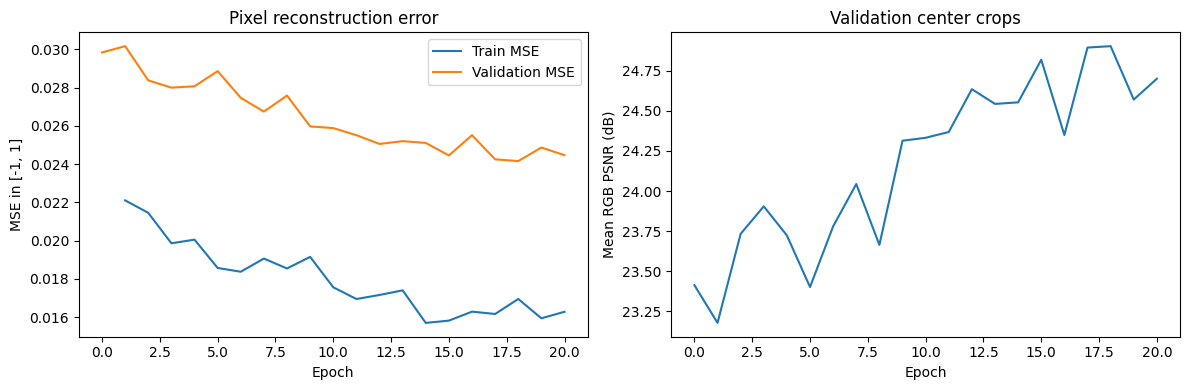

In [7]:
import matplotlib.pyplot as plt

history = state["history"]
trained = [row for row in history if row["train_mse"] is not None]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([r["epoch"] for r in trained], [r["train_mse"] for r in trained], label="Train MSE")
axes[0].plot([r["epoch"] for r in history], [r["val_mse"] for r in history], label="Validation MSE")
axes[0].set(xlabel="Epoch", ylabel="MSE in [-1, 1]", title="Pixel reconstruction error")
axes[0].legend()
axes[1].plot([r["epoch"] for r in history], [r["val_psnr_rgb"] for r in history])
axes[1].set(xlabel="Epoch", ylabel="Mean RGB PSNR (dB)", title="Validation center crops")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "pretrain_learning_curves.png", dpi=160)
plt.show()


## 7. Compare the transferred source, full-data generator, and bicubic
The exact same validation crops are used. The source column appears when the original source checkpoint is still available and matches the recorded fingerprint.

Bicubic is a fixed baseline. The full-data model is not guaranteed to beat it after 20 epochs. HR is the original reference.


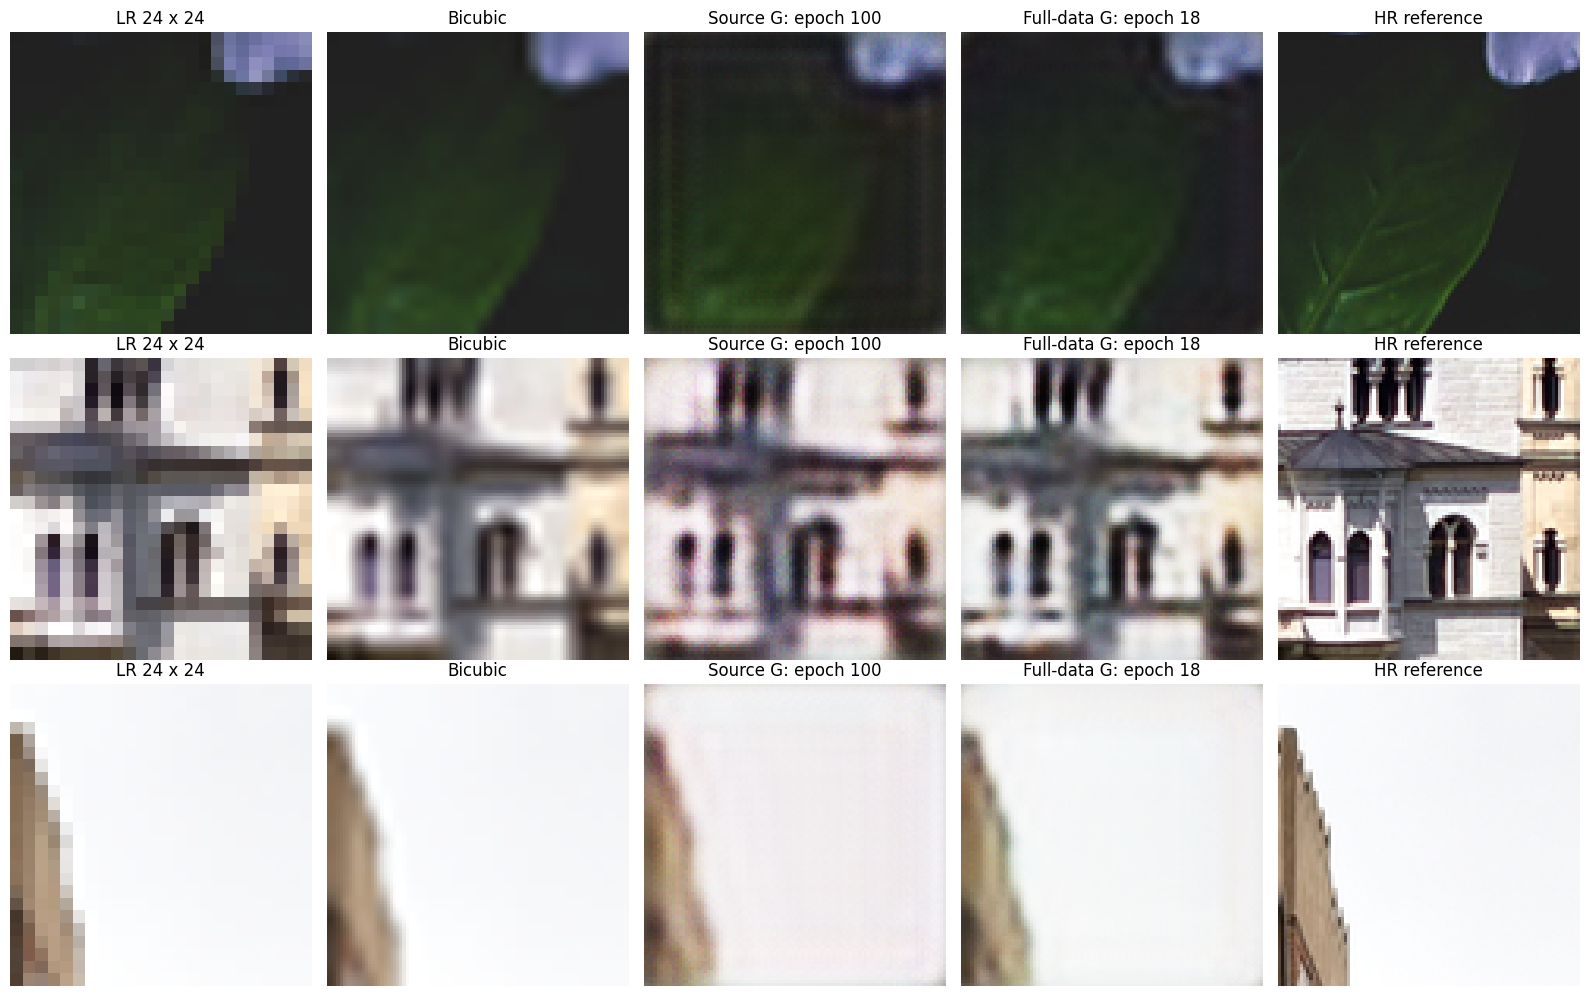

Bicubic: MSE=0.023353, RGB PSNR=26.01 dB
Transferred baseline: MSE=0.029843, RGB PSNR=23.41 dB
Best full-data G: MSE=0.024161, RGB PSNR=24.90 dB


In [8]:
import numpy as np
from PIL import Image
from src.pretrain import validate
from torch.utils.data import DataLoader

generator.load_state_dict(state["best_model"])
generator.eval()
with torch.inference_mode():
    best_sr = generator(preview_lr).cpu()

def rgb_image(tensor):
    return ((tensor + 1) / 2).clamp(0, 1).permute(1, 2, 0).numpy()

columns = 5 if initial_sr is not None else 4
fig, axes = plt.subplots(3, columns, figsize=(3.2 * columns, 10))
for row, (lr, hr) in enumerate(preview_pairs):
    lr_image = lr.permute(1, 2, 0).numpy()
    bicubic = Image.fromarray(np.rint(lr_image * 255).astype(np.uint8)).resize(
        (96, 96), Image.Resampling.BICUBIC
    )
    panels = [(lr_image, "LR 24 x 24"), (bicubic, "Bicubic")]
    if initial_sr is not None:
        panels.append((rgb_image(initial_sr[row]), f"Source G: epoch {source_preview_epoch}"))
    panels.extend([
        (rgb_image(best_sr[row]), f"Full-data G: epoch {state['best_epoch']}"),
        (rgb_image(hr), "HR reference"),
    ])
    for col, (image, title) in enumerate(panels):
        axes[row, col].imshow(image, interpolation="nearest")
        axes[row, col].set_title(title)
        axes[row, col].axis("off")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "pretrain_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Same 50 validation crops and Pillow bicubic policy as the visual baseline.
bicubic_mses, bicubic_psnrs = [], []
for lr, hr in validation_dataset:
    array = np.rint(lr.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    baseline = Image.fromarray(array).resize((96, 96), Image.Resampling.BICUBIC)
    baseline_tensor = torch.from_numpy(np.array(baseline, dtype=np.float32).transpose(2, 0, 1).copy()) / 255
    target = (hr + 1) / 2
    mse01 = (baseline_tensor - target).square().mean().item()
    bicubic_mses.append(mse01 * 4)
    bicubic_psnrs.append(-10 * np.log10(max(mse01, 1e-12)))
best_metrics = validate(
    generator, DataLoader(validation_dataset, batch_size=pretrain["batch_size"], num_workers=0), device
)
print(f"Bicubic: MSE={np.mean(bicubic_mses):.6f}, RGB PSNR={np.mean(bicubic_psnrs):.2f} dB")
print(f"Transferred baseline: MSE={state['history'][0]['val_mse']:.6f}, RGB PSNR={state['history'][0]['val_psnr_rgb']:.2f} dB")
print(f"Best full-data G: MSE={best_metrics['val_mse']:.6f}, RGB PSNR={best_metrics['val_psnr_rgb']:.2f} dB")


## 8. Save the full-data report
Compare the best full-data metrics against the transferred baseline and bicubic. No improvement threshold is assumed, and completing the notebook does not imply convergence.

Save the executed notebook to GitHub and share the results before choosing more pretraining or adversarial phase 4B.


In [9]:
from src.pretrain import atomic_json_save

report.update({
    "git_commit": commit, "run_id": RUN_ID, "pretrain_settings": pretrain,
    "completed_epoch": state["epoch"], "best_epoch": state["best_epoch"],
    "transferred_validation_baseline": state["history"][0],
    "initialization": state["initialization"],
    "best_generator_validation": best_metrics,
    "bicubic_validation": {
        "val_mse": float(np.mean(bicubic_mses)),
        "val_psnr_rgb": float(np.mean(bicubic_psnrs)),
    },
    "validation_protocol": "50 fixed RGB 96x96 center crops; no border shave; mean per-image PSNR",
    "checkpoint": str(RUN_DIR / "last.pt"),
    "best_weights": str(RUN_DIR / "best_generator.pt"),
    "test_used": False,
})
atomic_json_save(report, RESULTS_DIR / "pretrain_report.json")
print("Phase 4A full-data run complete: validation and checkpoints saved.")
print("Results:", RESULTS_DIR)
print("Next: compare against the source baseline and bicubic before phase 4B.")


Phase 4A full-data run complete: validation and checkpoints saved.
Results: /content/drive/MyDrive/SRGAN-Image-Super-Resolution/results/pretrain_full_v1_full800
Next: compare against the source baseline and bicubic before phase 4B.
